In [40]:
import os
from typing import TypedDict, Annotated

from dotenv import load_dotenv
from langchain_groq import ChatGroq
from langgraph.graph import END, START, StateGraph
from pydantic import BaseModel, Field
import operator


In [41]:
load_dotenv()
groq_api_key = os.getenv("GROQ_API_KEY")
model_name = os.getenv("GROQ_MODEL")

In [42]:
model = ChatGroq(model=model_name, temperature=0) 

In [43]:
class EvaluationSchema(BaseModel):

    feedback: str = Field(description='Detailed feedback for the essay')
    score: float = Field(
      description="Score out of 10 (can be a decimal, e.g., 8.5)"
  )

In [44]:
structured_model = model.with_structured_output(EvaluationSchema)

In [45]:
essay = """
A society's technological and economic advancements are often loud and visible, but its true character is whispered in the margins—how it safeguards those who cannot speak, run, or stand on equal footing. In an era obsessed with GDP growth, artificial intelligence, and corporate metrics, civilization risks mistaking material accumulation for moral evolution. The genuine index of a nation's progress is not found in its skyscrapers or military might, but in its institutional and empathetic commitment to its marginalized, elderly, differently-abled, and destitute.

Ancient Indian ethos encapsulated this through concepts like Antyodaya (the rise of the last person) and Vasudhaiva Kutumbakam (the world is one family). Figures like Mahatma Gandhi famously advocated for the "last man," arguing that policy must be measured by its impact on the poorest. Thinkers like John Rawls introduced the "veil of ignorance"—arguing that a just society is one we would design if we didn't know what position we’d occupy in it. Justice, therefore, requires prioritizing the least advantaged. Modern governance has similarly transitioned from treating the vulnerable as objects of pity or charity to rights-bearing citizens entitled to dignity, social security, and inclusion.

In the 21st century, vulnerability takes multiple complex forms. There is the economic margin of extreme poverty, informal labor exploitation, and urban homelessness, where workers lack safety nets or health insurance despite booming digital economies. There is social vulnerability, such as the elderly facing loneliness in a fast-nuclearizing world, alongside women and children susceptible to systemic violence and malnutrition. Furthermore, the digital divide creates a new kind of disenfranchisement as governance moves online, leaving behind the illiterate and rural poor. Climate change adds another layer of vulnerability, disproportionately affecting indigenous communities, low-income coastal populations, and agricultural laborers who bear the brunt of environmental shocks.

However, developing nations often grapple with a cruel triage—balancing capital-intensive infrastructure like defense, high-speed rail, and tech parks against immediate social welfare demands. Critics argue that excessive entitlement schemes can strain fiscal prudence and hamper long-term capital formation. Unchecked populism or direct-benefit handovers, if not carefully structured, can also risk creating a cycle of dependency rather than structural empowerment through skill, education, and market access.

Addressing these challenges requires institutionalizing empathy by strengthening social safety nets, including universal basic health coverage, robust pension schemes, and legal aid accessibility. Bridging the digital divide via localized UI, community digital literacy hubs, and assisted-tech centers ensures that digital transformation leaves no one behind. Empowering grassroots governance through Gram Panchayats and urban local bodies, combined with active civil society participation, helps identify the hidden vulnerable who slip through macro-level census cracks.

Ultimately, a nation’s height is measured not by how high its elite can climb, but by how deep a safety net it casts for those who fall. Technology and wealth provide the tools, but empathy provides the compass, ensuring that a humane society remains the ultimate legacy worth building.
"""

In [55]:
# prompt = f'Evaluate the language quality of the following essay and provide a feedback and assign a score out of 10 \n {essay}'
# structured_model.invoke(prompt)

In [47]:
class UPSCState(TypedDict):

    essay: str
    language_feedback: str
    anaylsis_feedback : str
    clarity_feedback: str
    overall_feedback: str
    individual_scores: Annotated[list[int], operator.add]
    avg_score: float
    

In [48]:
def evaluate_language(state: UPSCState):

    prompt = f'Evaluate the language quality of the following essay and provide a feedback and assign a score out of 10 \n {state['essay']}'
    output = structured_model.invoke(prompt)

    return {'language_feedback': output.feedback, 'individual_scores': [output.score]}




In [49]:
def evaluate_anaylsis(state: UPSCState):

    prompt = f'Evaluate the depth of anaylsis of the following essay and provide a feedback and assign a score out of 10 \n {state['essay']}'
    output = structured_model.invoke(prompt)

    return {'anaylsis_feedback': output.feedback, 'individual_scores': [output.score]}




In [50]:
def evaluate_thought(state: UPSCState):

    prompt = f'Evaluate the clarity of thought of the following essay and provide a feedback and assign a score out of 10 \n {state['essay']}'
    output = structured_model.invoke(prompt)

    return {'clarity_feedback': output.feedback, 'individual_scores': [output.score]}




In [56]:
def final_evaluation(state: UPSCState):

    #summary feedback 
    prompt =  f'Based on the following feedbacks create a summarized feedback \n language feedback - {state["language_feedback"]} \n depth of analysis feedback - {state["anaylsis_feedback"]} \n clarity of thought feedback - {state["clarity_feedback"]}'
    overall_feedback = model.invoke(prompt).content


    #avg calculate
    avg_score = sum(state['individual_scores'])/len(state['individual_scores'])

    return ({'overall_feedback': overall_feedback, 'avg_score': round(avg_score, 2)})

  





In [57]:
graph = StateGraph(UPSCState)

# add nodes

graph.add_node('evaluate_language', evaluate_language)
graph.add_node('evaluate_anaylsis', evaluate_anaylsis)
graph.add_node('evaluate_thought', evaluate_thought)
graph.add_node('final_evaluation', final_evaluation)

# add edges

graph.add_edge(START, 'evaluate_language')
graph.add_edge(START, 'evaluate_anaylsis')
graph.add_edge(START, 'evaluate_thought')

graph.add_edge('evaluate_language', 'final_evaluation')
graph.add_edge('evaluate_anaylsis', 'final_evaluation')
graph.add_edge('evaluate_thought', 'final_evaluation')

graph.add_edge('final_evaluation', END)

workflow = graph.compile()


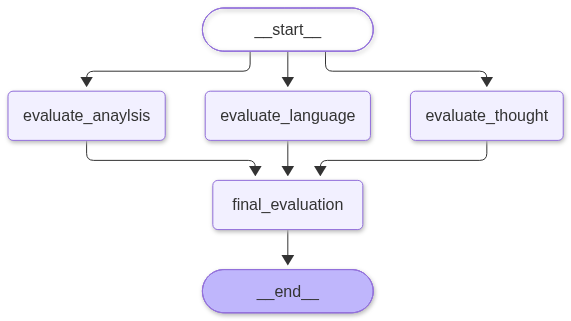

In [53]:
workflow

In [58]:
intitial_state = {
    'essay': essay
}

workflow.invoke(intitial_state)

{'essay': '\nA society\'s technological and economic advancements are often loud and visible, but its true character is whispered in the margins—how it safeguards those who cannot speak, run, or stand on equal footing. In an era obsessed with GDP growth, artificial intelligence, and corporate metrics, civilization risks mistaking material accumulation for moral evolution. The genuine index of a nation\'s progress is not found in its skyscrapers or military might, but in its institutional and empathetic commitment to its marginalized, elderly, differently-abled, and destitute.\n\nAncient Indian ethos encapsulated this through concepts like Antyodaya (the rise of the last person) and Vasudhaiva Kutumbakam (the world is one family). Figures like Mahatma Gandhi famously advocated for the "last man," arguing that policy must be measured by its impact on the poorest. Thinkers like John Rawls introduced the "veil of ignorance"—arguing that a just society is one we would design if we didn\'t k